# 🌀 Custom RealNVP (600 Epochs)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DiveshJ8/Generative_Deep_Learning_2nd_Edition/blob/feature/assignment_5/notebooks/06_normflow/01_realnvp/realnvp_modified.ipynb)

In this notebook, we build a **custom `Coupling` layer** (stacking `Dense` layers to create the scale output $s$ and a separate set of `Dense` layers to create the translation output $t$) and a **custom `RealNVP` Keras `Model`**, train the network for **600 epochs**, visualize the **training loss curve**, and compare the custom 600-epoch results against the original 300-epoch baseline (`realnvp.ipynb`).

In [1]:
# Setup for Google Colab and local environments
import os
import sys

# Configure TensorFlow to use legacy Keras 2 (tf_keras) required by TensorFlow Probability
os.environ["TF_USE_LEGACY_KERAS"] = "1"

# Python 3.12+ compatibility fix: 'imp' was removed in Python 3.12+, but legacy extensions may import it
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types
        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# 1. If running in Google Colab, clone the repository branch and navigate into it
if "google.colab" in sys.modules:
    if os.path.exists("/content"):
        %cd /content
    if not os.path.exists("Generative_Deep_Learning_2nd_Edition"):
        !git clone -b feature/assignment_5 https://github.com/DiveshJ8/Generative_Deep_Learning_2nd_Edition.git || git clone https://github.com/DiveshJ8/Generative_Deep_Learning_2nd_Edition.git
    %cd /content/Generative_Deep_Learning_2nd_Edition
    if os.path.abspath(".") not in sys.path:
        sys.path.append(os.path.abspath("."))
    # Install required packages in Colab (tf-keras is required for TFP compatibility on TF 2.16+)
    %pip install -q scikit-learn tensorflow-probability tf-keras tensorboard matplotlib

# 2. Add repository root to sys.path if running locally outside repository root
repo_root = None
for candidate in [
    os.path.abspath(os.path.join(os.getcwd(), "../../..")),
    os.path.abspath(os.getcwd()),
    os.path.abspath("/content/Generative_Deep_Learning_2nd_Edition"),
    "/app",
]:
    if os.path.exists(os.path.join(candidate, "notebooks")):
        repo_root = candidate
        break
if repo_root is None:
    repo_root = os.path.abspath(os.path.join(os.getcwd(), "../../.."))

if repo_root not in sys.path:
    sys.path.append(repo_root)

# 3. Ensure required packages are installed
try:
    import sklearn
except ImportError:
    %pip install -q scikit-learn

try:
    import tensorflow
except ImportError:
    %pip install -q tensorflow

try:
    import tensorflow_probability
except ImportError:
    %pip install -q tensorflow-probability

try:
    import tf_keras
except ImportError:
    %pip install -q tf-keras

try:
    import tensorboard
except ImportError:
    %pip install -q tensorboard

try:
    import matplotlib
except ImportError:
    %pip install -q matplotlib


/content
/content/Generative_Deep_Learning_2nd_Edition


The code has been adapted from the excellent [RealNVP tutorial](https://keras.io/examples/generative/real_nvp) created by Mandolini Giorgio Maria, Sanna Daniele and Zannini Quirini Giorgio available on the Keras website.

In [2]:
# Configure Keras to use legacy tf_keras for compatibility with TensorFlow Probability
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

# Python 3.12+ compatibility shim for 'imp' (used by legacy autoreload)
import sys
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types
        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# Enable autoreload if available and supported
try:
    %load_ext autoreload
    %autoreload 2
except Exception:
    pass

import numpy as np
import matplotlib.pyplot as plt

from sklearn import datasets

import tensorflow as tf
try:
    import tf_keras as keras
    from tf_keras import (
        layers,
        models,
        regularizers,
        metrics,
        optimizers,
        callbacks,
    )
except (ImportError, ModuleNotFoundError):
    from tensorflow.keras import (
        layers,
        models,
        regularizers,
        metrics,
        optimizers,
        callbacks,
    )
import tensorflow_probability as tfp

print(f"TensorFlow version: {tf.__version__}")
gpus = tf.config.list_physical_devices("GPU")
tpus = tf.config.list_physical_devices("TPU")
print(f"GPU available: {bool(gpus)}")
if gpus:
    print(f"🚀 Using GPU: {gpus[0].name}")
elif tpus:
    print(f"⚡ TPU detected: {tpus[0].name}")
else:
    print("⚠️ No GPU detected (running on CPU). In Google Colab, go to: Runtime -> Change runtime type -> T4 GPU (Hardware Accelerator).")

TensorFlow version: 2.21.0
GPU available: True
🚀 Using GPU: /physical_device:GPU:0


## 0. Parameters & Output Directories <a name="parameters"></a>

We configure the custom RealNVP network to train for **`EPOCHS = 600`** (doubled from `300` in the original notebook) and use **`COUPLING_LAYERS = 6`** (3 alternating pairs of `[0, 1]` and `[1, 0]` affine coupling masks, matching the Keras RealNVP reference architecture) so that both dimensions $(x_1, x_2)$ undergo multi-stage non-linear shearing and scaling. Dedicated output directories (`./output_modified` and `./logs_modified`) are used to preserve the original baseline artifacts.

In [3]:
COUPLING_DIM = 256
COUPLING_LAYERS = 6       # 3 alternating pairs of [0, 1] and [1, 0] coupling layers (vs. 2 in original)
INPUT_DIM = 2
REGULARIZATION = 0.01
BATCH_SIZE = 256
EPOCHS = 600              # Train for 600 epochs as required (vs. 300 in original)
LEARNING_RATE = 0.0001

# Dedicated output and log directories for the custom 600-epoch run
OUTPUT_DIR = "./output_modified"
LOG_DIR = "./logs_modified"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

print(f"Configuration: EPOCHS={EPOCHS}, COUPLING_LAYERS={COUPLING_LAYERS}, COUPLING_DIM={COUPLING_DIM}, BATCH_SIZE={BATCH_SIZE}")
print(f"Output directory: {os.path.abspath(OUTPUT_DIR)}")

Configuration: EPOCHS=600, COUPLING_LAYERS=6, COUPLING_DIM=256, BATCH_SIZE=256
Output directory: /content/Generative_Deep_Learning_2nd_Edition/output_modified


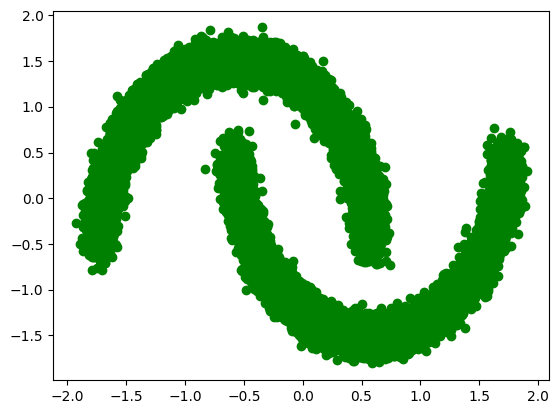

In [4]:
# Load the data
data = datasets.make_moons(30000, noise=0.05)[0].astype("float32")
norm = layers.Normalization()
norm.adapt(data)
normalized_data = norm(data)
plt.scatter(
    normalized_data.numpy()[:, 0], normalized_data.numpy()[:, 1], c="green"
)
plt.show()

## 2. Build the Custom Coupling Layer & RealNVP Network <a name="build"></a>

To build a custom `Coupling` layer for our example:
1. **Scale Network ($s$)**: We stack 4 hidden `Dense` layers (`coupling_dim = 256`, `activation="relu"`, $L_2$ regularization) followed by an output `Dense` layer (`input_dim = 2`, `activation="tanh"`) to bound the log-scale factor $s(x_{\text{masked}}) \in (-1, 1)$ and prevent exponential overflow in $\exp(\pm s)$.
2. **Translation Network ($t$)**: We stack a separate, independent set of 4 hidden `Dense` layers (`coupling_dim = 256`, `activation="relu"`, $L_2$ regularization) followed by an output `Dense` layer (`input_dim = 2`, `activation="linear"`) to allow unconstrained spatial shifts $t(x_{\text{masked}}) \in (-\infty, \infty)$.
3. **Custom Keras `Model` (`RealNVP`)**: Subclasses `models.Model` to chain the `Coupling` layers with alternating binary masks `[[0, 1], [1, 0]]`, computing exact log-determinant Jacobians $\log|\det J_{f}(x)| = -\sum s$ during training ($x \to z$, `direction = -1`) and running the inverse transformation during generation ($z \to x$, `direction = +1`).

In [5]:
class CustomCoupling(layers.Layer):
    """Custom Coupling layer stacking Dense layers for scale (s) and a separate set of Dense layers for translation (t)."""

    def __init__(self, input_dim, coupling_dim, reg, **kwargs):
        super(CustomCoupling, self).__init__(**kwargs)
        self.input_dim = input_dim
        self.coupling_dim = coupling_dim
        self.reg = reg

        # Stacked Dense layers to create the scale (s) output
        self.s_layer_1 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.s_layer_2 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.s_layer_3 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.s_layer_4 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.s_layer_5 = layers.Dense(
            input_dim, activation="tanh", kernel_regularizer=regularizers.l2(reg)
        )

        # Separate set of stacked Dense layers to create the translation (t) output
        self.t_layer_1 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.t_layer_2 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.t_layer_3 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.t_layer_4 = layers.Dense(
            coupling_dim, activation="relu", kernel_regularizer=regularizers.l2(reg)
        )
        self.t_layer_5 = layers.Dense(
            input_dim, activation="linear", kernel_regularizer=regularizers.l2(reg)
        )

    def call(self, inputs):
        # Forward pass through the scale (s) Dense stack
        s = self.s_layer_1(inputs)
        s = self.s_layer_2(s)
        s = self.s_layer_3(s)
        s = self.s_layer_4(s)
        s = self.s_layer_5(s)

        # Forward pass through the translation (t) Dense stack
        t = self.t_layer_1(inputs)
        t = self.t_layer_2(t)
        t = self.t_layer_3(t)
        t = self.t_layer_4(t)
        t = self.t_layer_5(t)

        return [s, t]


def Coupling(input_dim, coupling_dim, reg):
    """Builds a functional Keras Model wrapping the stacked scale (s) and translation (t) Dense branches."""
    input_layer = layers.Input(shape=(input_dim,))
    s_output, t_output = CustomCoupling(input_dim, coupling_dim, reg)(input_layer)
    return models.Model(inputs=input_layer, outputs=[s_output, t_output])

In [6]:
class RealNVP(models.Model):
    def __init__(
        self, input_dim, coupling_layers, coupling_dim, regularization
    ):
        super(RealNVP, self).__init__()
        self.coupling_layers = coupling_layers
        self.distribution = tfp.distributions.MultivariateNormalDiag(
            loc=[0.0, 0.0], scale_diag=[1.0, 1.0]
        )
        self.masks = np.array(
            [[0, 1], [1, 0]] * (coupling_layers // 2), dtype="float32"
        )
        self.loss_tracker = metrics.Mean(name="loss")
        self.layers_list = [
            Coupling(input_dim, coupling_dim, regularization)
            for i in range(coupling_layers)
        ]

    @property
    def metrics(self):
        return [self.loss_tracker]

    def call(self, x, training=True):
        log_det_inv = 0
        direction = 1
        if training:
            direction = -1
        for i in range(self.coupling_layers)[::direction]:
            x_masked = x * self.masks[i]
            reversed_mask = 1 - self.masks[i]
            s, t = self.layers_list[i](x_masked)
            s *= reversed_mask
            t *= reversed_mask
            gate = (direction - 1) / 2
            x = (
                reversed_mask
                * (x * tf.exp(direction * s) + direction * t * tf.exp(gate * s))
                + x_masked
            )
            log_det_inv += gate * tf.reduce_sum(s, axis=1)
        return x, log_det_inv

    def log_loss(self, x):
        y, logdet = self(x)
        log_likelihood = self.distribution.log_prob(y) + logdet
        return -tf.reduce_mean(log_likelihood)

    def train_step(self, data):
        with tf.GradientTape() as tape:
            loss = self.log_loss(data)
        g = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(g, self.trainable_variables))
        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

    def test_step(self, data):
        loss = self.log_loss(data)
        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}


model = RealNVP(
    input_dim=INPUT_DIM,
    coupling_layers=COUPLING_LAYERS,
    coupling_dim=COUPLING_DIM,
    regularization=REGULARIZATION,
)
# Build model weights with a dummy forward pass and print parameter count
_ = model(normalized_data[:2])
print(f"✅ Custom RealNVP model built with {COUPLING_LAYERS} Coupling layers | Total trainable parameters: {model.count_params():,}")

✅ Custom RealNVP model built with 6 Coupling layers | Total trainable parameters: 2,383,898


## 3. Train the RealNVP Network (600 Epochs) <a name="train"></a>

We compile the custom `RealNVP` model with the Adam optimizer (`learning_rate = 0.0001`) and train for **600 epochs** while recording the training loss history (`history`) and saving intermediate distribution snapshots (`Data space X`, `f(X)`, `Latent space Z`, and `g(Z)`).

In [7]:
# Compile the custom RealNVP model
model.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE))

In [8]:
import os

os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

tensorboard_callback = callbacks.TensorBoard(log_dir=LOG_DIR, profile_batch=0)


class ImageGenerator(callbacks.Callback):
    def __init__(self, num_samples):
        super(ImageGenerator, self).__init__()
        self.num_samples = num_samples

    def generate(self):
        # From data to latent space: f(X) -> Z (direction = -1)
        z, _ = model(normalized_data, training=True)

        # From latent space to data: g(Z) -> X (direction = +1)
        samples = model.distribution.sample(self.num_samples)
        x, _ = model(samples, training=False)

        return x.numpy(), z.numpy(), samples.numpy()

    def display(self, x, z, samples, save_to=None):
        f, axes = plt.subplots(2, 2)
        f.set_size_inches(8, 5)

        axes[0, 0].scatter(
            normalized_data[:, 0], normalized_data[:, 1], color="r", s=1
        )
        axes[0, 0].set(title="Data space X", xlabel="x_1", ylabel="x_2")
        axes[0, 0].set_xlim([-2, 2])
        axes[0, 0].set_ylim([-2, 2])
        axes[0, 1].scatter(z[:, 0], z[:, 1], color="r", s=1)
        axes[0, 1].set(title="f(X)", xlabel="z_1", ylabel="z_2")
        axes[0, 1].set_xlim([-2, 2])
        axes[0, 1].set_ylim([-2, 2])
        axes[1, 0].scatter(samples[:, 0], samples[:, 1], color="g", s=1)
        axes[1, 0].set(title="Latent space Z", xlabel="z_1", ylabel="z_2")
        axes[1, 0].set_xlim([-2, 2])
        axes[1, 0].set_ylim([-2, 2])
        axes[1, 1].scatter(x[:, 0], x[:, 1], color="g", s=1)
        axes[1, 1].set(title="g(Z)", xlabel="x_1", ylabel="x_2")
        axes[1, 1].set_xlim([-2, 2])
        axes[1, 1].set_ylim([-2, 2])

        plt.subplots_adjust(wspace=0.3, hspace=0.6)
        if save_to:
            os.makedirs(os.path.dirname(save_to) or ".", exist_ok=True)
            plt.savefig(save_to, dpi=150, bbox_inches="tight")
            print(f"\nSaved to {save_to}")

        plt.show()

    def on_epoch_end(self, epoch, logs=None):
        if epoch % 20 == 0 or epoch == EPOCHS - 1:
            x, z, samples = self.generate()
            self.display(
                x,
                z,
                samples,
                save_to=os.path.join(OUTPUT_DIR, f"generated_img_{epoch:03d}.png"),
            )


img_generator_callback = ImageGenerator(num_samples=3000)

Epoch 1/600
  4/118 [>.............................] - ETA: 2s - loss: 2.7584   

118/118 [==============================] - ETA: 0s - loss: 2.4296
Saved to ./output_modified/generated_img_000.png


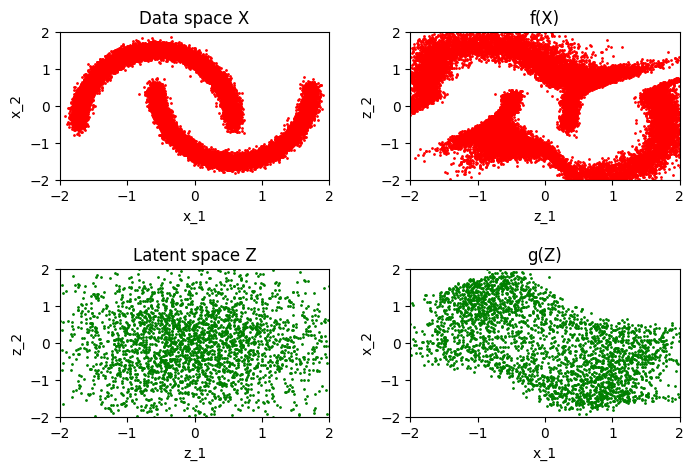

118/118 [==============================] - 24s 34ms/step - loss: 2.4296
Epoch 2/600
118/118 [==============================] - 2s 19ms/step - loss: 2.1040
Epoch 3/600
118/118 [==============================] - 2s 19ms/step - loss: 1.8529
Epoch 4/600
118/118 [==============================] - 2s 19ms/step - loss: 1.5540
Epoch 5/600
118/118 [==============================] - 2s 19ms/step - loss: 1.4894
Epoch 6/600
118/118 [==============================] - 2s 19ms/step - loss: 1.4713
Epoch 7/600
118/118 [==============================] - 2s 19ms/step - loss: 1.4295
Epoch 8/600
118/118 [==============================] - 2s 19ms/step - loss: 1.4157
Epoch 9/600
118/118 [==============================] - 2s 19ms/step - loss: 1.4037
Epoch 10/600
118/118 [==============================] - 2s 20ms/step - loss: 1.3852
Epoch 11/600
118/118 [==============================] - 2s 19ms/step - loss: 1.4153
Epoch 12/600
118/118 [==============================] - 2s 18ms/step - loss: 1.4069
Epoch 13/600

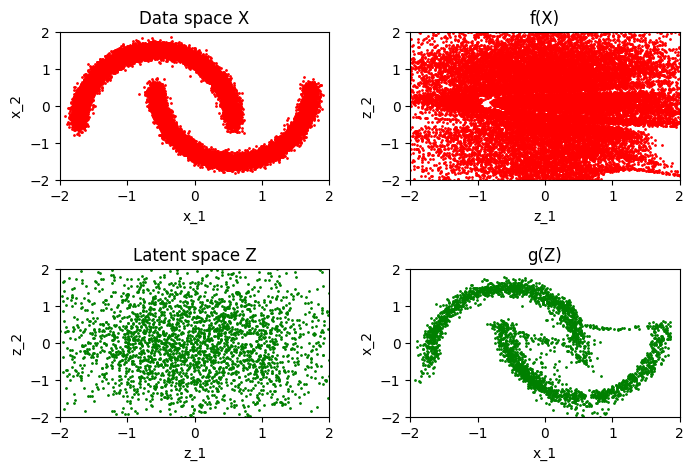

118/118 [==============================] - 4s 30ms/step - loss: 1.3901
Epoch 22/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3560
Epoch 23/600
118/118 [==============================] - 2s 20ms/step - loss: 1.3463
Epoch 24/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3260
Epoch 25/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3281
Epoch 26/600
118/118 [==============================] - 2s 20ms/step - loss: 1.3195
Epoch 27/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3090
Epoch 28/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3052
Epoch 29/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3210
Epoch 30/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3454
Epoch 31/600
118/118 [==============================] - 2s 20ms/step - loss: 1.3386
Epoch 32/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3021
Epoch

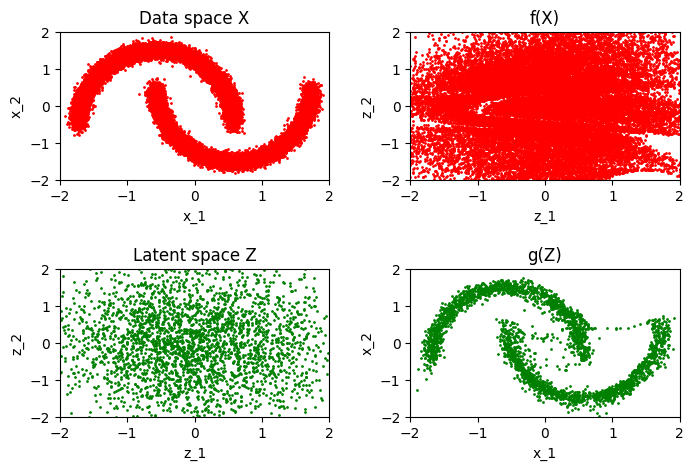

118/118 [==============================] - 3s 28ms/step - loss: 1.2908
Epoch 42/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2907
Epoch 43/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2958
Epoch 44/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2946
Epoch 45/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3053
Epoch 46/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2895
Epoch 47/600
118/118 [==============================] - 2s 20ms/step - loss: 1.2992
Epoch 48/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2926
Epoch 49/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2894
Epoch 50/600
118/118 [==============================] - 2s 18ms/step - loss: 1.3680
Epoch 51/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2971
Epoch 52/600
118/118 [==============================] - 2s 20ms/step - loss: 1.2811
Epoch

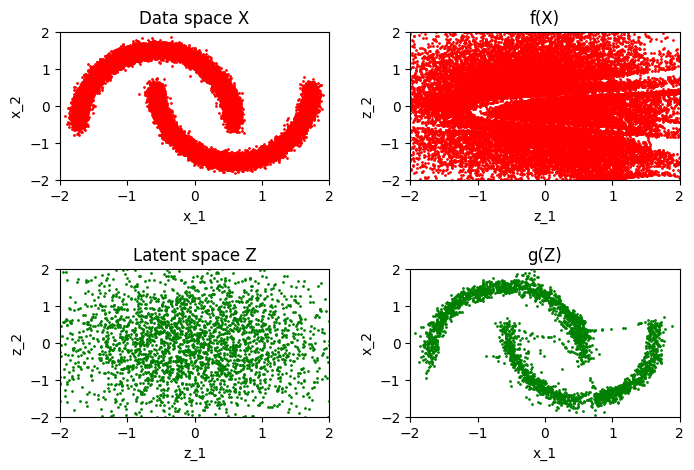

118/118 [==============================] - 3s 28ms/step - loss: 1.3193
Epoch 62/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2908
Epoch 63/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2890
Epoch 64/600
118/118 [==============================] - 2s 19ms/step - loss: 1.3023
Epoch 65/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2962
Epoch 66/600
118/118 [==============================] - 2s 18ms/step - loss: 1.3144
Epoch 67/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2868
Epoch 68/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2802
Epoch 69/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2764
Epoch 70/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2717
Epoch 71/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2680
Epoch 72/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2688
Epoch

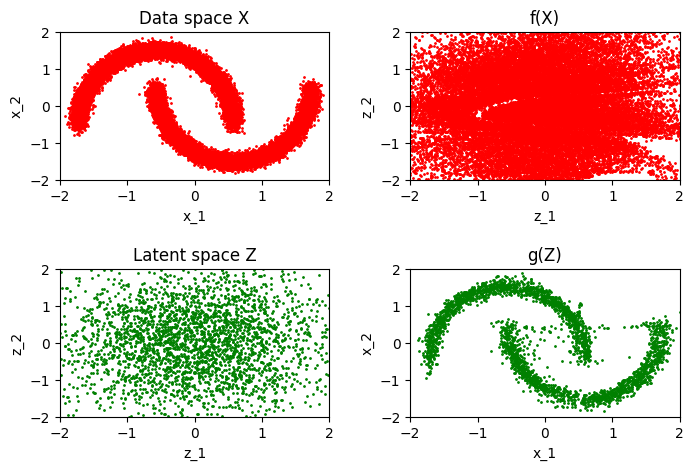

118/118 [==============================] - 3s 28ms/step - loss: 1.2778
Epoch 82/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2738
Epoch 83/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2720
Epoch 84/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2746
Epoch 85/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2786
Epoch 86/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2999
Epoch 87/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2799
Epoch 88/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2942
Epoch 89/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2733
Epoch 90/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2646
Epoch 91/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2634
Epoch 92/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2927
Epoch

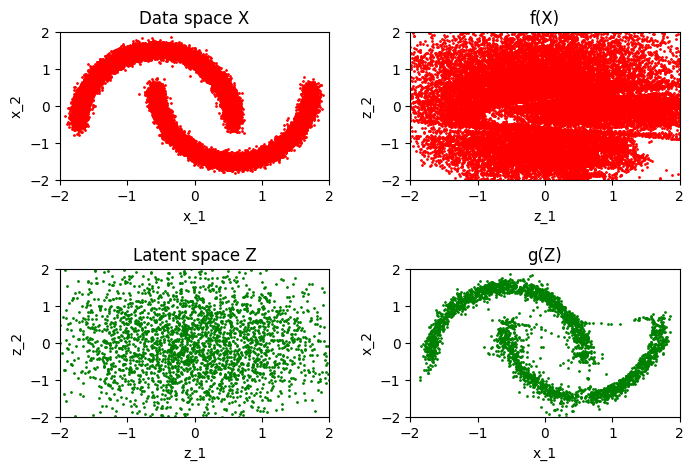

118/118 [==============================] - 3s 28ms/step - loss: 1.2855
Epoch 102/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2922
Epoch 103/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2629
Epoch 104/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2744
Epoch 105/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2800
Epoch 106/600
118/118 [==============================] - 2s 18ms/step - loss: 1.3377
Epoch 107/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2804
Epoch 108/600
118/118 [==============================] - 2s 18ms/step - loss: 1.3106
Epoch 109/600
118/118 [==============================] - 2s 18ms/step - loss: 1.4652
Epoch 110/600
118/118 [==============================] - 2s 18ms/step - loss: 1.5628
Epoch 111/600
118/118 [==============================] - 2s 19ms/step - loss: 1.4250
Epoch 112/600
118/118 [==============================] - 2s 18ms/step - loss: 1

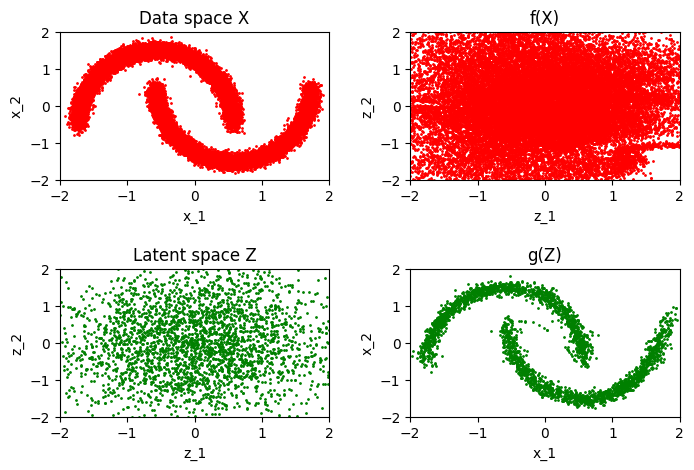

118/118 [==============================] - 3s 29ms/step - loss: 1.2133
Epoch 122/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2122
Epoch 123/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2074
Epoch 124/600
118/118 [==============================] - 2s 18ms/step - loss: 1.2125
Epoch 125/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1996
Epoch 126/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1983
Epoch 127/600
118/118 [==============================] - 2s 19ms/step - loss: 1.2004
Epoch 128/600
118/118 [==============================] - 2s 17ms/step - loss: 1.2026
Epoch 129/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1938
Epoch 130/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1880
Epoch 131/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1863
Epoch 132/600
118/118 [==============================] - 2s 19ms/step - loss: 1

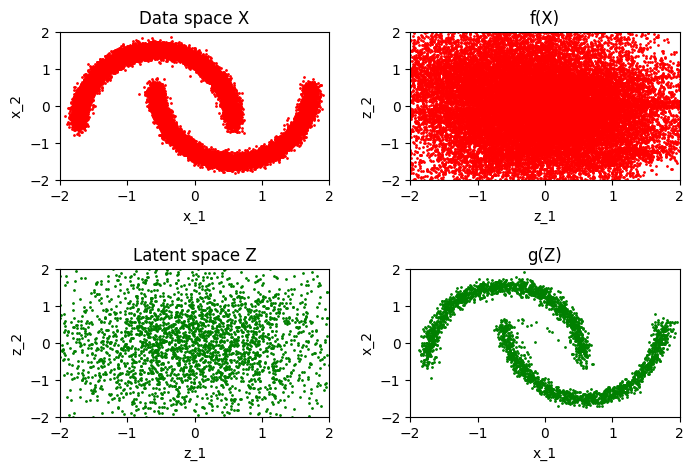

118/118 [==============================] - 3s 28ms/step - loss: 1.1787
Epoch 142/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1895
Epoch 143/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1744
Epoch 144/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1786
Epoch 145/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1793
Epoch 146/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1761
Epoch 147/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1799
Epoch 148/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1773
Epoch 149/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1780
Epoch 150/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1759
Epoch 151/600
118/118 [==============================] - 2s 17ms/step - loss: 1.1783
Epoch 152/600
118/118 [==============================] - 2s 18ms/step - loss: 1

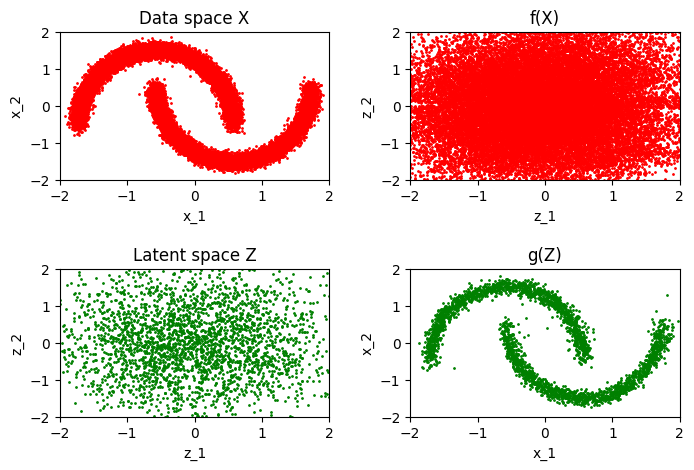

118/118 [==============================] - 3s 27ms/step - loss: 1.1767
Epoch 162/600
118/118 [==============================] - 2s 17ms/step - loss: 1.1711
Epoch 163/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1710
Epoch 164/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1751
Epoch 165/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1750
Epoch 166/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1748
Epoch 167/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1807
Epoch 168/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1758
Epoch 169/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1694
Epoch 170/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1759
Epoch 171/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1750
Epoch 172/600
118/118 [==============================] - 2s 18ms/step - loss: 1

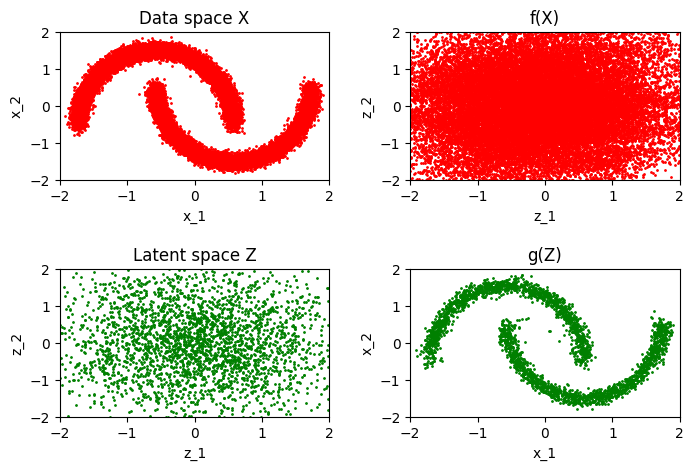

118/118 [==============================] - 3s 29ms/step - loss: 1.1675
Epoch 182/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1663
Epoch 183/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1697
Epoch 184/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1741
Epoch 185/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1722
Epoch 186/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1720
Epoch 187/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1696
Epoch 188/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1747
Epoch 189/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1763
Epoch 190/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1680
Epoch 191/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1720
Epoch 192/600
118/118 [==============================] - 2s 18ms/step - loss: 1

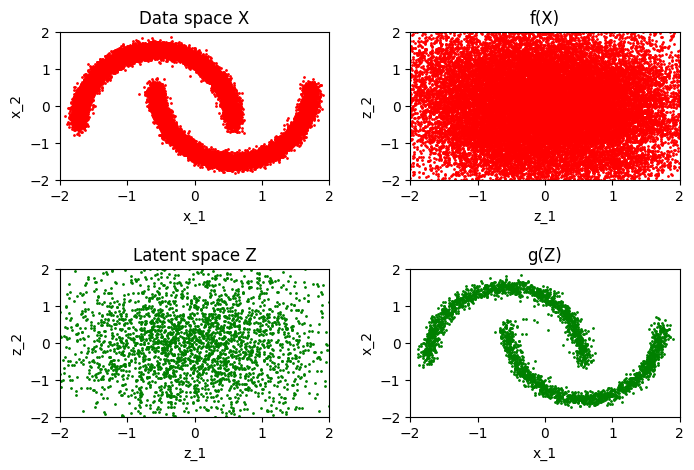

118/118 [==============================] - 3s 28ms/step - loss: 1.1784
Epoch 202/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1706
Epoch 203/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1719
Epoch 204/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1702
Epoch 205/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1829
Epoch 206/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1674
Epoch 207/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1667
Epoch 208/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1768
Epoch 209/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1687
Epoch 210/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1659
Epoch 211/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1643
Epoch 212/600
118/118 [==============================] - 2s 18ms/step - loss: 1

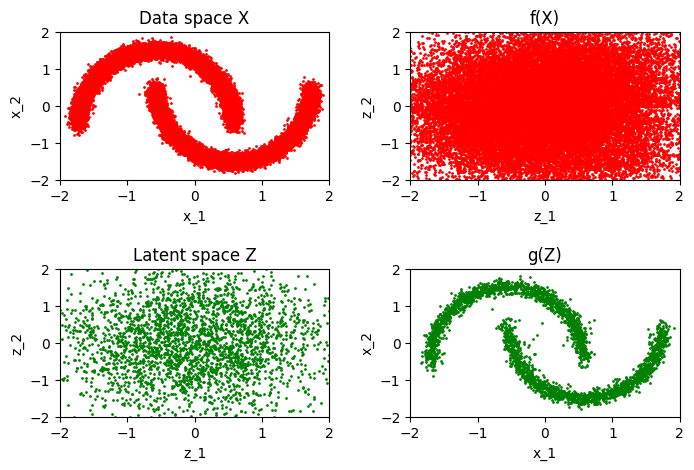

118/118 [==============================] - 3s 28ms/step - loss: 1.1863
Epoch 222/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1615
Epoch 223/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1698
Epoch 224/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1868
Epoch 225/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1653
Epoch 226/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1660
Epoch 227/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1686
Epoch 228/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1727
Epoch 229/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1655
Epoch 230/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1688
Epoch 231/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1664
Epoch 232/600
118/118 [==============================] - 2s 20ms/step - loss: 1

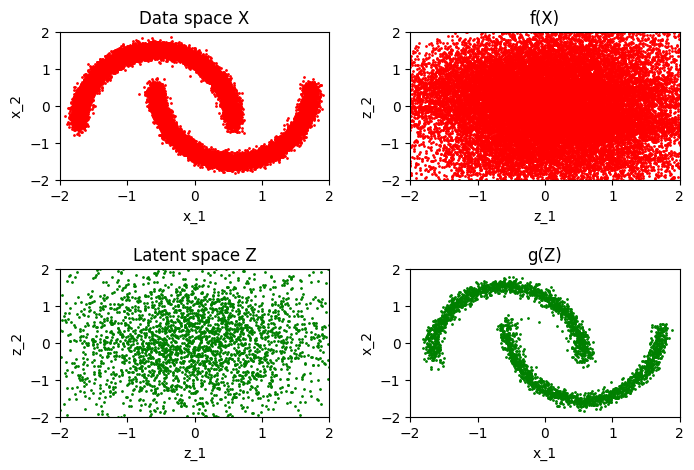

118/118 [==============================] - 3s 28ms/step - loss: 1.1615
Epoch 242/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1632
Epoch 243/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1685
Epoch 244/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1604
Epoch 245/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1655
Epoch 246/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1653
Epoch 247/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1653
Epoch 248/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1642
Epoch 249/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1651
Epoch 250/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1666
Epoch 251/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1662
Epoch 252/600
118/118 [==============================] - 2s 18ms/step - loss: 1

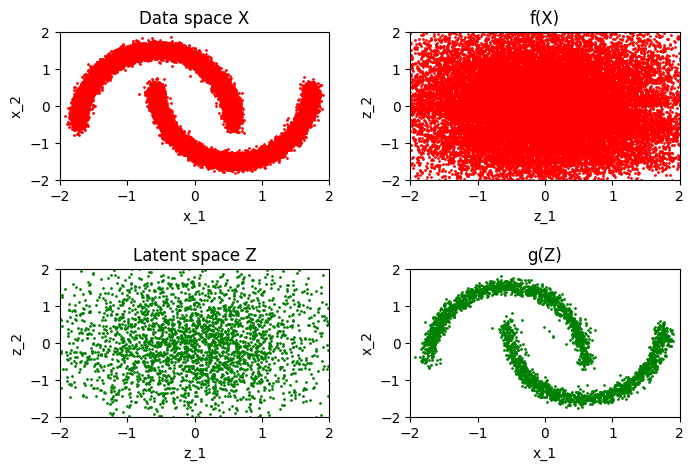

118/118 [==============================] - 3s 28ms/step - loss: 1.1702
Epoch 262/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1629
Epoch 263/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1643
Epoch 264/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1657
Epoch 265/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1622
Epoch 266/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1646
Epoch 267/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1639
Epoch 268/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1611
Epoch 269/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1698
Epoch 270/600
118/118 [==============================] - 2s 21ms/step - loss: 1.1663
Epoch 271/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1577
Epoch 272/600
118/118 [==============================] - 2s 20ms/step - loss: 1

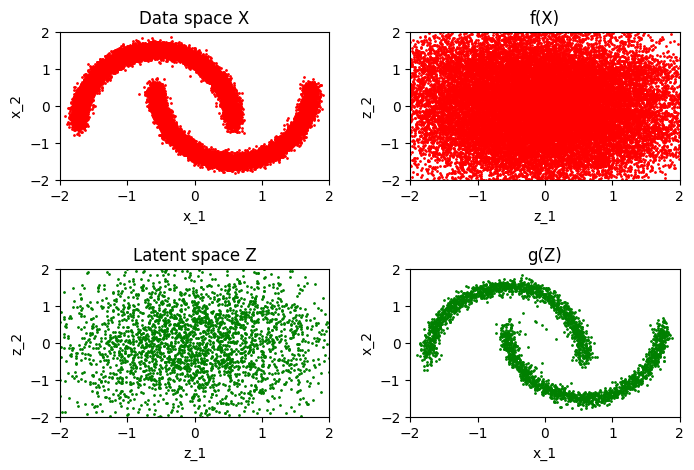

118/118 [==============================] - 3s 29ms/step - loss: 1.1612
Epoch 282/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1686
Epoch 283/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1673
Epoch 284/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1758
Epoch 285/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1646
Epoch 286/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1633
Epoch 287/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1662
Epoch 288/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1611
Epoch 289/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1681
Epoch 290/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1610
Epoch 291/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1659
Epoch 292/600
118/118 [==============================] - 2s 19ms/step - loss: 1

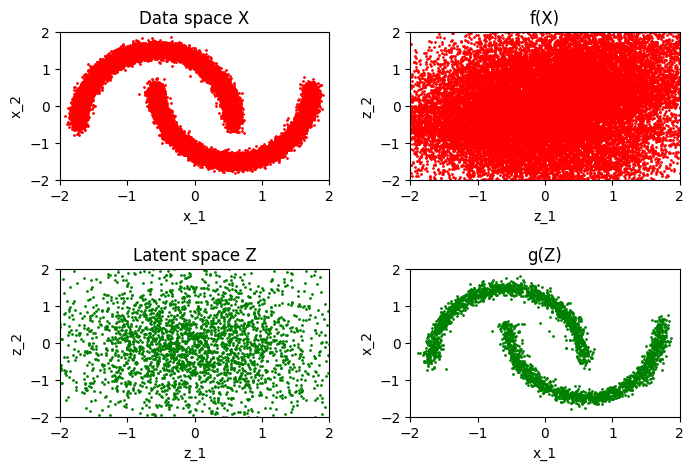

118/118 [==============================] - 3s 29ms/step - loss: 1.1631
Epoch 302/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1631
Epoch 303/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1617
Epoch 304/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1572
Epoch 305/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1654
Epoch 306/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1605
Epoch 307/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1651
Epoch 308/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1626
Epoch 309/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1603
Epoch 310/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1594
Epoch 311/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1642
Epoch 312/600
118/118 [==============================] - 2s 18ms/step - loss: 1

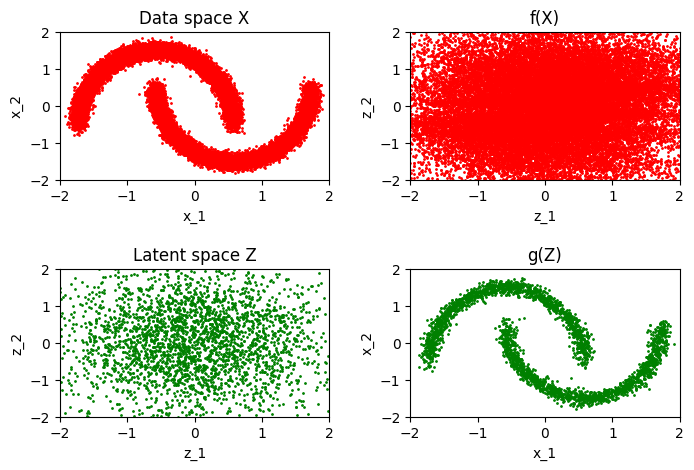

118/118 [==============================] - 3s 29ms/step - loss: 1.1619
Epoch 322/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1592
Epoch 323/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1612
Epoch 324/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1597
Epoch 325/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1621
Epoch 326/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1576
Epoch 327/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1659
Epoch 328/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1633
Epoch 329/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1676
Epoch 330/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1617
Epoch 331/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1614
Epoch 332/600
118/118 [==============================] - 2s 19ms/step - loss: 1

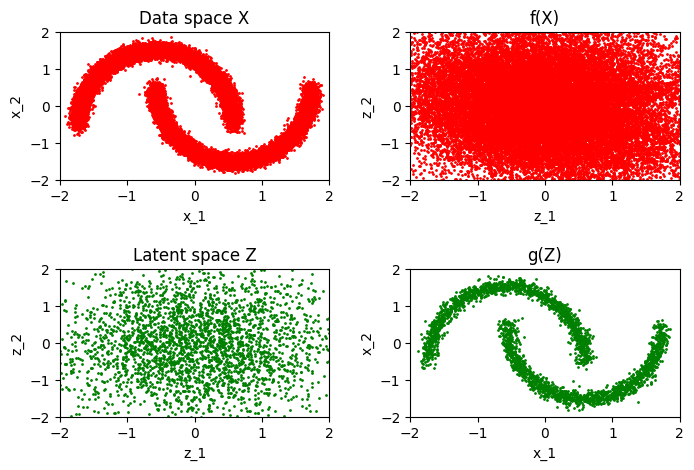

118/118 [==============================] - 3s 29ms/step - loss: 1.1584
Epoch 342/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1599
Epoch 343/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1636
Epoch 344/600
118/118 [==============================] - 2s 21ms/step - loss: 1.1590
Epoch 345/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1646
Epoch 346/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1605
Epoch 347/600
118/118 [==============================] - 2s 21ms/step - loss: 1.1592
Epoch 348/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1608
Epoch 349/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1646
Epoch 350/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1595
Epoch 351/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1577
Epoch 352/600
118/118 [==============================] - 2s 21ms/step - loss: 1

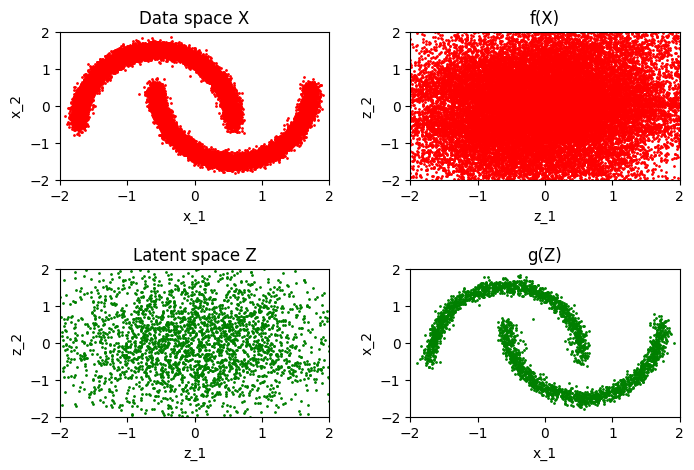

118/118 [==============================] - 3s 28ms/step - loss: 1.1565
Epoch 362/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1578
Epoch 363/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1585
Epoch 364/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1603
Epoch 365/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1563
Epoch 366/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1595
Epoch 367/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1581
Epoch 368/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1611
Epoch 369/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1591
Epoch 370/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1579
Epoch 371/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1606
Epoch 372/600
118/118 [==============================] - 2s 19ms/step - loss: 1

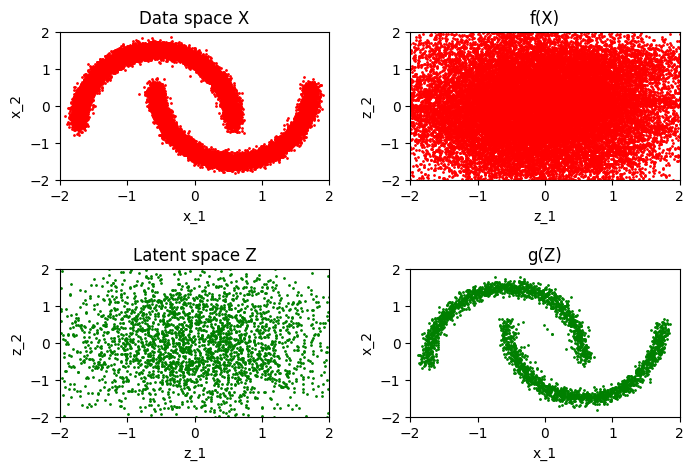

118/118 [==============================] - 3s 28ms/step - loss: 1.1598
Epoch 382/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1578
Epoch 383/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1599
Epoch 384/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1609
Epoch 385/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1589
Epoch 386/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1582
Epoch 387/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1620
Epoch 388/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1570
Epoch 389/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1583
Epoch 390/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1580
Epoch 391/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1593
Epoch 392/600
118/118 [==============================] - 2s 18ms/step - loss: 1

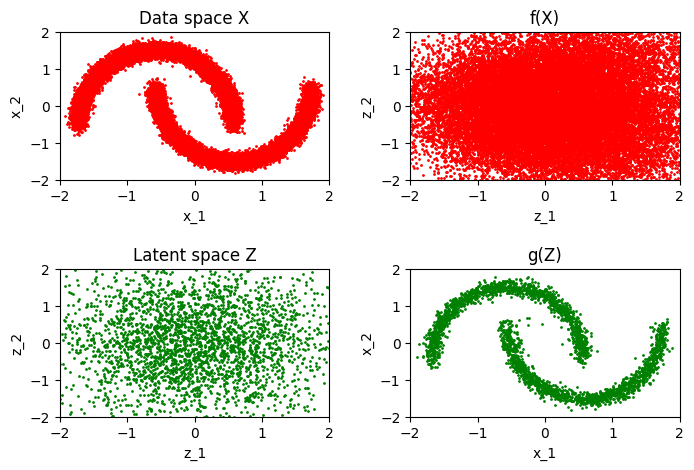

118/118 [==============================] - 3s 28ms/step - loss: 1.1618
Epoch 402/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1571
Epoch 403/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1604
Epoch 404/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1562
Epoch 405/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1657
Epoch 406/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1582
Epoch 407/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1608
Epoch 408/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1631
Epoch 409/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1580
Epoch 410/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1546
Epoch 411/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1580
Epoch 412/600
118/118 [==============================] - 2s 18ms/step - loss: 1

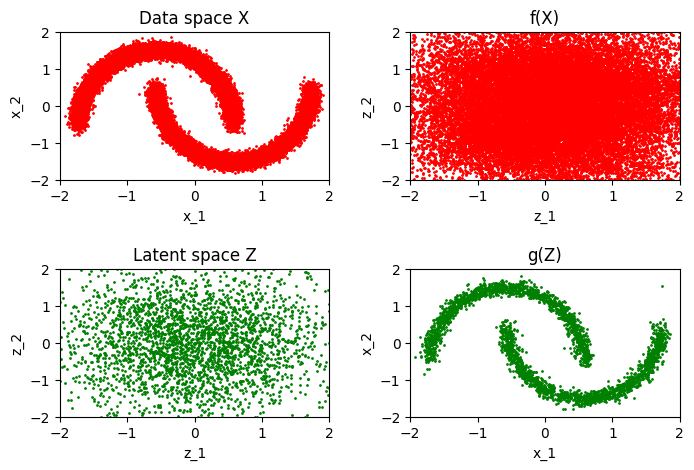

118/118 [==============================] - 3s 28ms/step - loss: 1.1595
Epoch 422/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1556
Epoch 423/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1559
Epoch 424/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1572
Epoch 425/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1508
Epoch 426/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1592
Epoch 427/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1555
Epoch 428/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1646
Epoch 429/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1600
Epoch 430/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1578
Epoch 431/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1571
Epoch 432/600
118/118 [==============================] - 2s 18ms/step - loss: 1

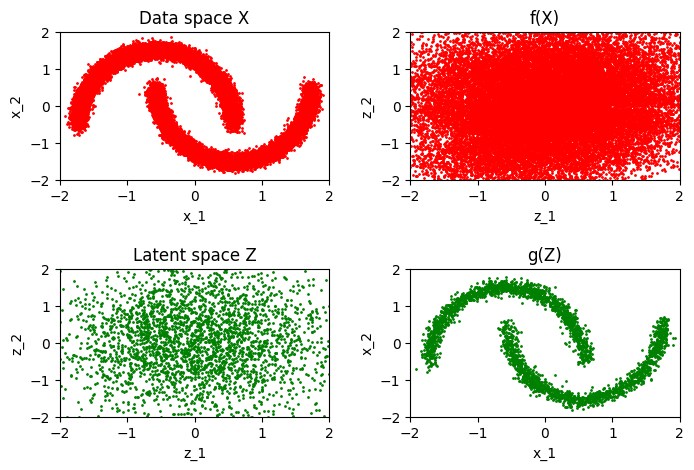

118/118 [==============================] - 3s 29ms/step - loss: 1.1591
Epoch 442/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1569
Epoch 443/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1569
Epoch 444/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1540
Epoch 445/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1554
Epoch 446/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1566
Epoch 447/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1591
Epoch 448/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1561
Epoch 449/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1543
Epoch 450/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1529
Epoch 451/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1629
Epoch 452/600
118/118 [==============================] - 2s 19ms/step - loss: 1

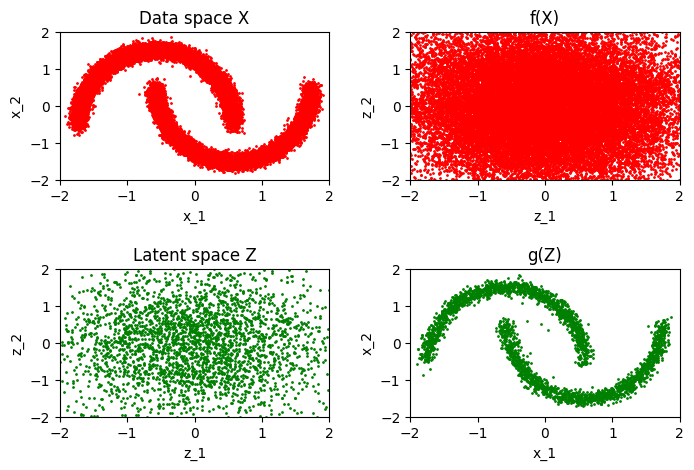

118/118 [==============================] - 3s 28ms/step - loss: 1.1626
Epoch 462/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1557
Epoch 463/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1516
Epoch 464/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1565
Epoch 465/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1601
Epoch 466/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1564
Epoch 467/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1568
Epoch 468/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1554
Epoch 469/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1570
Epoch 470/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1559
Epoch 471/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1558
Epoch 472/600
118/118 [==============================] - 2s 18ms/step - loss: 1

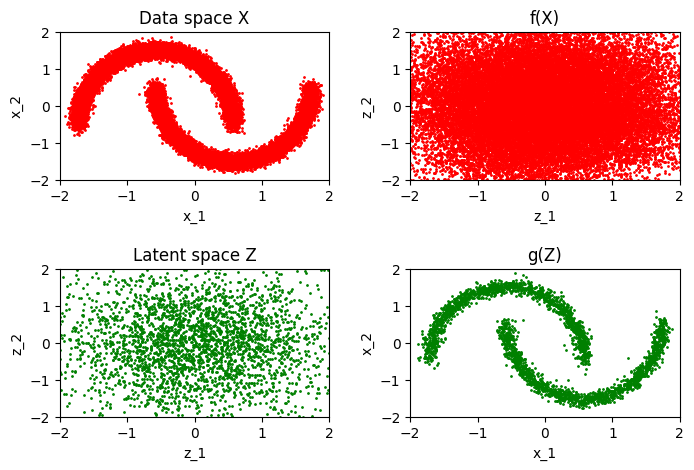

118/118 [==============================] - 3s 29ms/step - loss: 1.1514
Epoch 482/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1554
Epoch 483/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1579
Epoch 484/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1520
Epoch 485/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1526
Epoch 486/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1568
Epoch 487/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1617
Epoch 488/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1525
Epoch 489/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1528
Epoch 490/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1535
Epoch 491/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1534
Epoch 492/600
118/118 [==============================] - 2s 18ms/step - loss: 1

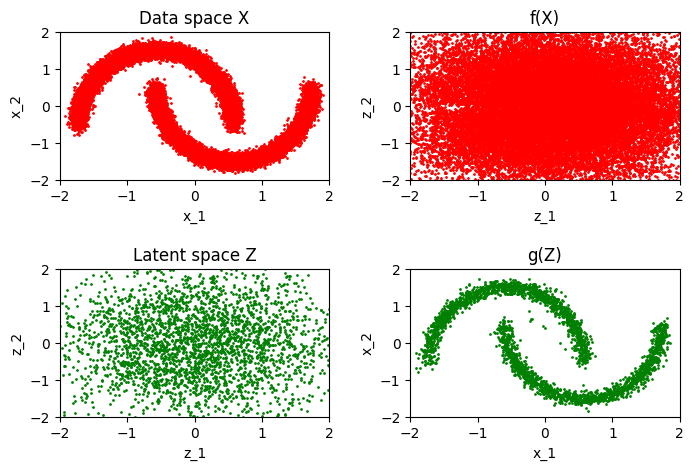

118/118 [==============================] - 3s 28ms/step - loss: 1.1545
Epoch 502/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1558
Epoch 503/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1604
Epoch 504/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1585
Epoch 505/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1531
Epoch 506/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1535
Epoch 507/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1564
Epoch 508/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1555
Epoch 509/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1563
Epoch 510/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1509
Epoch 511/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1572
Epoch 512/600
118/118 [==============================] - 2s 18ms/step - loss: 1

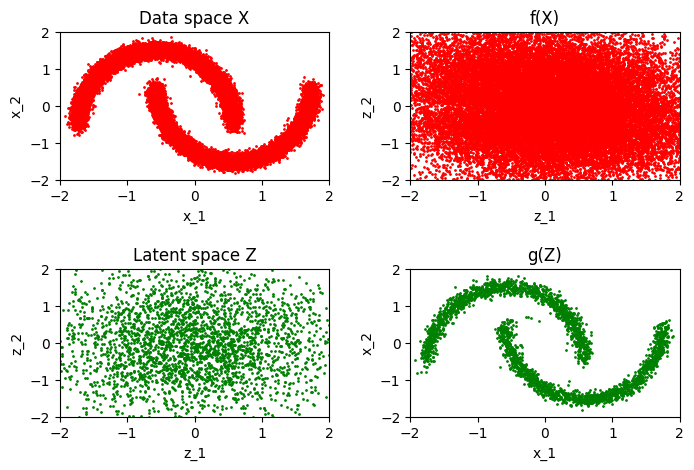

118/118 [==============================] - 3s 29ms/step - loss: 1.1557
Epoch 522/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1547
Epoch 523/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1493
Epoch 524/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1541
Epoch 525/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1555
Epoch 526/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1552
Epoch 527/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1526
Epoch 528/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1522
Epoch 529/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1552
Epoch 530/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1605
Epoch 531/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1563
Epoch 532/600
118/118 [==============================] - 2s 19ms/step - loss: 1

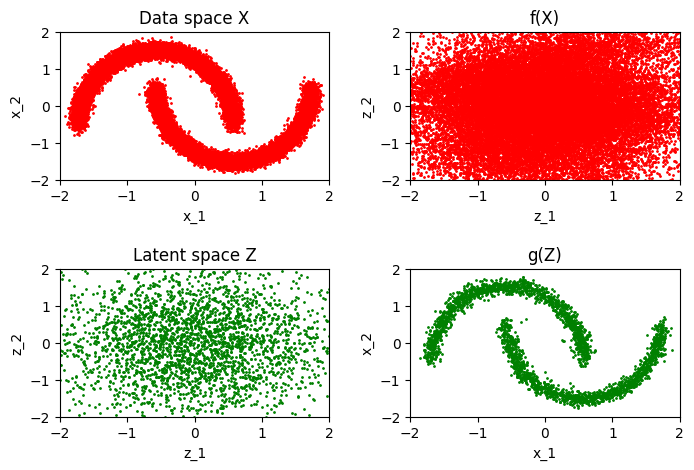

118/118 [==============================] - 3s 28ms/step - loss: 1.1500
Epoch 542/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1508
Epoch 543/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1536
Epoch 544/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1538
Epoch 545/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1491
Epoch 546/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1518
Epoch 547/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1520
Epoch 548/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1570
Epoch 549/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1569
Epoch 550/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1516
Epoch 551/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1493
Epoch 552/600
118/118 [==============================] - 2s 18ms/step - loss: 1

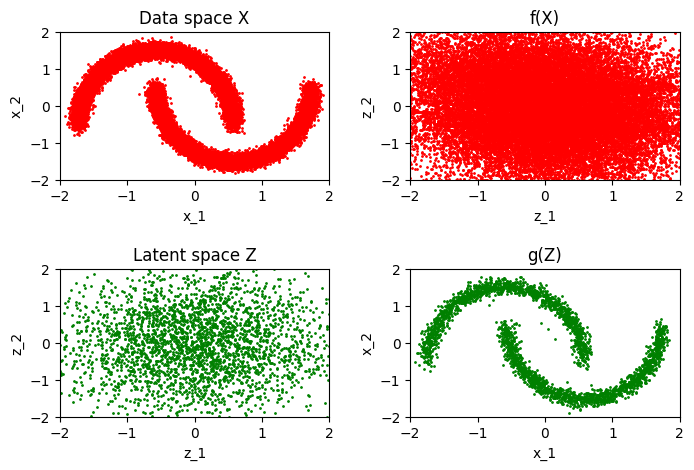

118/118 [==============================] - 3s 28ms/step - loss: 1.1553
Epoch 562/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1536
Epoch 563/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1537
Epoch 564/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1528
Epoch 565/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1527
Epoch 566/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1592
Epoch 567/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1530
Epoch 568/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1561
Epoch 569/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1527
Epoch 570/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1530
Epoch 571/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1559
Epoch 572/600
118/118 [==============================] - 2s 19ms/step - loss: 1

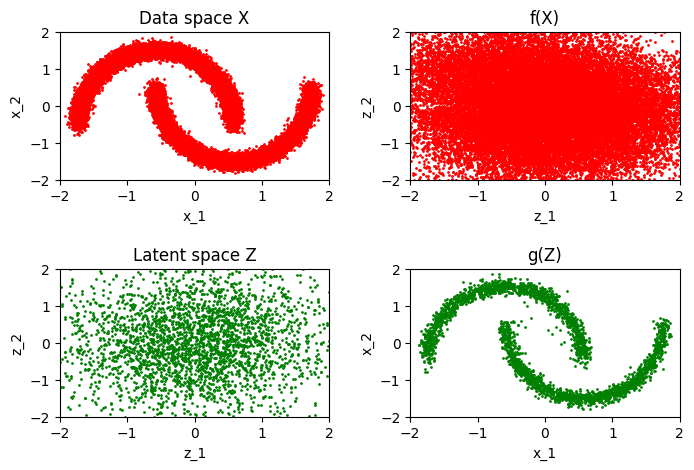

118/118 [==============================] - 3s 28ms/step - loss: 1.1499
Epoch 582/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1557
Epoch 583/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1529
Epoch 584/600
118/118 [==============================] - 2s 20ms/step - loss: 1.1513
Epoch 585/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1525
Epoch 586/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1542
Epoch 587/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1504
Epoch 588/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1543
Epoch 589/600
118/118 [==============================] - 2s 19ms/step - loss: 1.1529
Epoch 590/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1511
Epoch 591/600
118/118 [==============================] - 2s 18ms/step - loss: 1.1521
Epoch 592/600
118/118 [==============================] - 2s 18ms/step - loss: 1

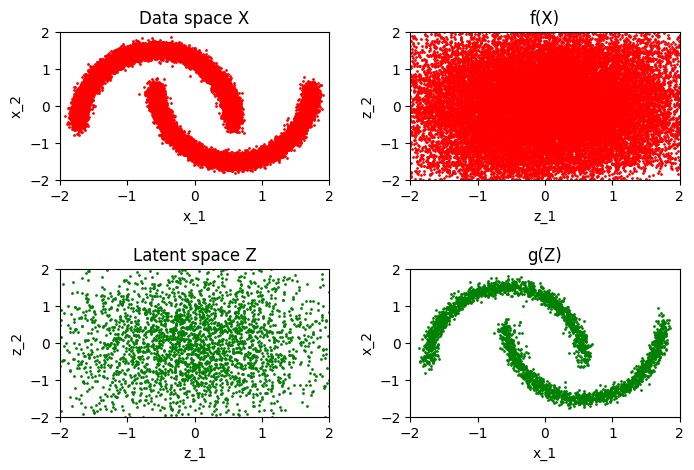

118/118 [==============================] - 3s 29ms/step - loss: 1.1538


In [9]:
history = model.fit(
    normalized_data,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[tensorboard_callback, img_generator_callback],
)

## 4. Training Loss Curve & Comparison with Original (300 Epochs) <a name="loss_curve"></a>

Below we plot:
1. **The 600-Epoch Training Loss Curve** of the custom RealNVP network (Negative Log-Likelihood in nats) with a 15-epoch moving average and key epoch annotations.
2. **A Direct Comparative Loss Plot (Custom 600 Epochs vs. Original 300 Epochs)** overlaying the custom network's 600-epoch trajectory against the original 300-epoch baseline trajectory from `realnvp.ipynb`, alongside a milestone bar chart and summary statistics table.

Saved training loss curve to ./output_modified/training_loss_curve_600_epochs.png


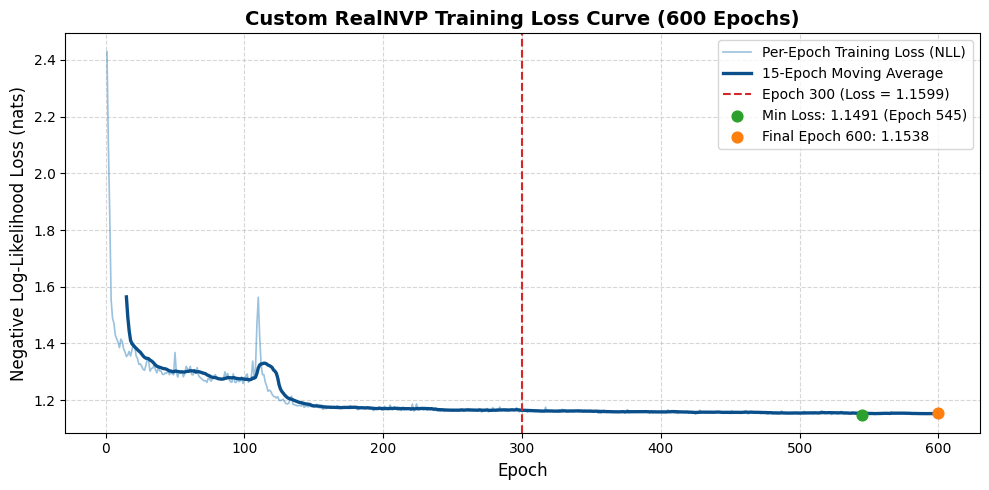

Saved comparative loss plot to ./output_modified/loss_comparison_custom_vs_original.png


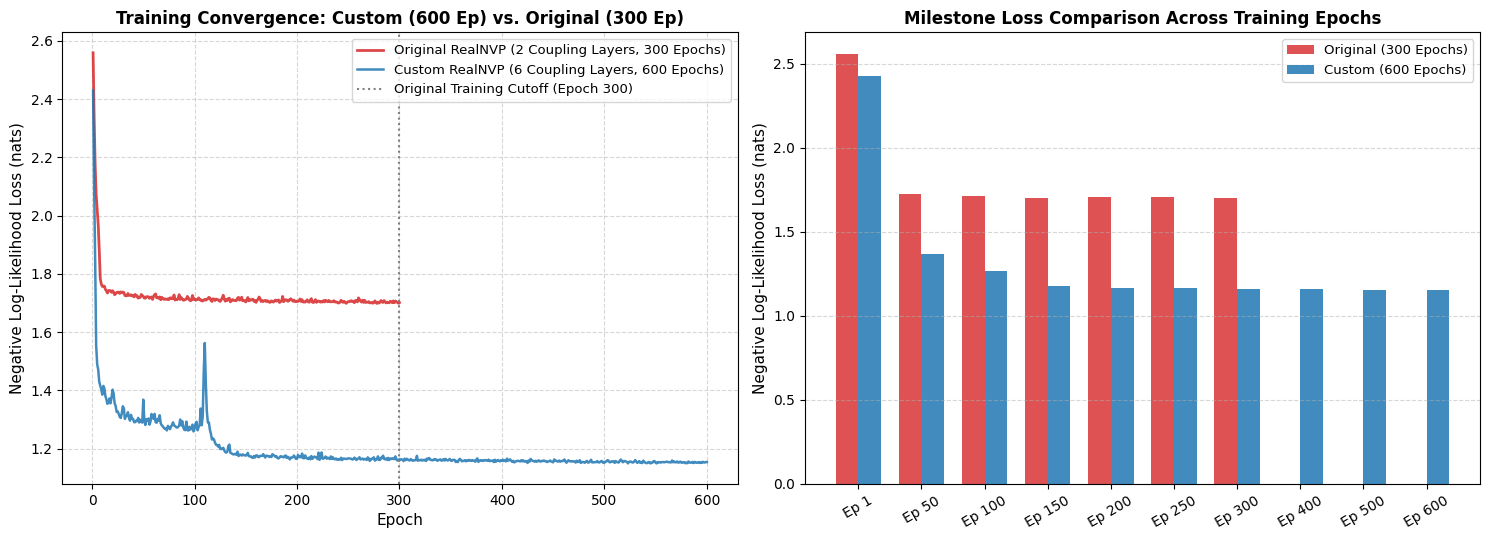

Epoch Milestone      | Original (300 Ep, 2 Layers) | Custom (600 Ep, 6 Layers)
------------------------------------------------------------------------------
Epoch 1              | 2.5590 nats                | 2.4296 nats
Epoch 50             | 1.7227 nats                | 1.3680 nats
Epoch 100            | 1.7142 nats                | 1.2699 nats
Epoch 150            | 1.7035 nats                | 1.1759 nats
Epoch 200            | 1.7051 nats                | 1.1660 nats
Epoch 250            | 1.7049 nats                | 1.1666 nats
Epoch 300            | 1.7014 nats                | 1.1599 nats
Epoch 400            | N/A (Stopped at 300)       | 1.1585 nats
Epoch 500            | N/A (Stopped at 300)       | 1.1521 nats
Epoch 600            | N/A (Stopped at 300)       | 1.1538 nats
------------------------------------------------------------------------------
Minimum Loss         | 1.6986 nats (Epoch 278)   | 1.1491 nats (Epoch 545)
Final Loss           | 1.7014 nats (Epoch 300)  

In [10]:
# Original 300-epoch baseline loss trajectory recorded from realnvp.ipynb (COUPLING_LAYERS=2, EPOCHS=300)
ORIGINAL_300_EPOCHS_LOSS = [
    2.559, 2.3386, 2.1729, 2.0724, 2.0177, 1.9688, 1.8826, 1.7836, 1.7652, 1.7566,
    1.7583, 1.7576, 1.7467, 1.7423, 1.7341, 1.7425, 1.743, 1.7422, 1.7366, 1.7421,
    1.7373, 1.7285, 1.7315, 1.7363, 1.7372, 1.7372, 1.7328, 1.7381, 1.7354, 1.7375,
    1.7363, 1.7261, 1.7248, 1.7253, 1.7327, 1.7257, 1.727, 1.7282, 1.724, 1.7266,
    1.7211, 1.7295, 1.7239, 1.7252, 1.7167, 1.7182, 1.7192, 1.7293, 1.7259, 1.7227,
    1.7168, 1.7165, 1.7217, 1.7214, 1.7215, 1.7162, 1.719, 1.7208, 1.7122, 1.7226,
    1.7286, 1.7312, 1.7177, 1.7188, 1.7159, 1.7209, 1.711, 1.7196, 1.7157, 1.7126,
    1.7144, 1.7129, 1.7125, 1.7144, 1.7116, 1.7174, 1.7179, 1.7144, 1.7145, 1.7276,
    1.71, 1.7131, 1.7111, 1.7159, 1.7287, 1.7121, 1.719, 1.7144, 1.7096, 1.7102,
    1.7122, 1.7133, 1.7227, 1.7174, 1.7107, 1.7074, 1.7102, 1.7258, 1.7122, 1.7142,
    1.7099, 1.7109, 1.7129, 1.7176, 1.7107, 1.7114, 1.7074, 1.7069, 1.7096, 1.7125,
    1.7099, 1.7125, 1.7148, 1.7195, 1.717, 1.709, 1.7053, 1.7146, 1.7134, 1.7086,
    1.7137, 1.7112, 1.7114, 1.7072, 1.7055, 1.7106, 1.7173, 1.7267, 1.7145, 1.7062,
    1.7122, 1.7084, 1.7157, 1.7165, 1.704, 1.7073, 1.7119, 1.7098, 1.7088, 1.7075,
    1.7087, 1.7169, 1.7192, 1.7097, 1.7124, 1.72, 1.7075, 1.7093, 1.7075, 1.7035,
    1.7113, 1.719, 1.7075, 1.7113, 1.7098, 1.712, 1.7132, 1.7059, 1.7091, 1.7021,
    1.7091, 1.7125, 1.7206, 1.7148, 1.7051, 1.7089, 1.7052, 1.7075, 1.7089, 1.7049,
    1.7081, 1.7058, 1.7025, 1.7026, 1.7074, 1.705, 1.7032, 1.7067, 1.7104, 1.7065,
    1.7074, 1.7106, 1.7016, 1.7058, 1.7062, 1.7226, 1.7045, 1.7092, 1.7115, 1.7107,
    1.706, 1.707, 1.7128, 1.7145, 1.7107, 1.7063, 1.7099, 1.7045, 1.7066, 1.7051,
    1.7055, 1.7079, 1.7138, 1.7052, 1.7112, 1.7031, 1.7043, 1.703, 1.7064, 1.711,
    1.704, 1.7026, 1.7105, 1.7151, 1.7027, 1.7017, 1.7044, 1.7118, 1.7021, 1.7063,
    1.7069, 1.7051, 1.703, 1.7057, 1.7032, 1.7084, 1.7037, 1.7093, 1.7066, 1.7044,
    1.7089, 1.7046, 1.7042, 1.7043, 1.7056, 1.7079, 1.7034, 1.7036, 1.7033, 1.7001,
    1.7003, 1.7027, 1.7094, 1.7049, 1.7021, 1.7058, 1.7021, 1.6988, 1.7026, 1.7049,
    1.7043, 1.7065, 1.7079, 1.7048, 1.706, 1.701, 1.7084, 1.7088, 1.7039, 1.7177,
    1.7117, 1.7066, 1.7031, 1.7095, 1.7022, 1.7093, 1.7019, 1.7028, 1.7024, 1.7047,
    1.7008, 1.7003, 1.7019, 1.6994, 1.7013, 1.7073, 1.7022, 1.6986, 1.7031, 1.6997,
    1.7028, 1.7086, 1.7033, 1.7019, 1.7083, 1.7036, 1.7002, 1.703, 1.7017, 1.7006,
    1.7063, 1.7043, 1.7011, 1.7072, 1.7011, 1.7069, 1.7044, 1.7019, 1.6993, 1.7014,
]

custom_losses = np.array(history.history["loss"], dtype=np.float64)
orig_losses = np.array(ORIGINAL_300_EPOCHS_LOSS, dtype=np.float64)
epochs_custom = np.arange(1, len(custom_losses) + 1)
epochs_orig = np.arange(1, len(orig_losses) + 1)

# Compute 15-epoch moving average for smooth trend visualization
window = 15
if len(custom_losses) >= window:
    kernel = np.ones(window) / window
    smoothed_custom = np.convolve(custom_losses, kernel, mode="valid")
    epochs_smoothed = np.arange(window, len(custom_losses) + 1)
else:
    smoothed_custom = custom_losses
    epochs_smoothed = epochs_custom

# 1. Standalone 600-Epoch Training Loss Curve
plt.figure(figsize=(10, 5))
plt.plot(epochs_custom, custom_losses, color="#1f77b4", alpha=0.45, linewidth=1.2, label="Per-Epoch Training Loss (NLL)")
plt.plot(epochs_smoothed, smoothed_custom, color="#0b4f8a", linewidth=2.4, label=f"{window}-Epoch Moving Average")
plt.axvline(x=300, color="#d62728", linestyle="--", linewidth=1.5, label=f"Epoch 300 (Loss = {custom_losses[min(299, len(custom_losses)-1)]:.4f})")

min_idx = int(np.argmin(custom_losses))
plt.scatter([min_idx + 1], [custom_losses[min_idx]], color="#2ca02c", s=60, zorder=5, label=f"Min Loss: {custom_losses[min_idx]:.4f} (Epoch {min_idx + 1})")
plt.scatter([len(custom_losses)], [custom_losses[-1]], color="#ff7f0e", s=60, zorder=5, label=f"Final Epoch {len(custom_losses)}: {custom_losses[-1]:.4f}")

plt.title("Custom RealNVP Training Loss Curve (600 Epochs)", fontsize=14, fontweight="bold")
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Negative Log-Likelihood Loss (nats)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=10, loc="upper right")
plt.tight_layout()
loss_curve_path = os.path.join(OUTPUT_DIR, "training_loss_curve_600_epochs.png")
plt.savefig(loss_curve_path, dpi=300, bbox_inches="tight")
print(f"Saved training loss curve to {loss_curve_path}")
plt.show()

# 2. Comparative Loss Plot: Custom (600 Epochs) vs. Original (300 Epochs)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(epochs_orig, orig_losses, color="#d62728", linewidth=2.0, alpha=0.85, label="Original RealNVP (2 Coupling Layers, 300 Epochs)")
axes[0].plot(epochs_custom, custom_losses, color="#1f77b4", linewidth=1.8, alpha=0.85, label="Custom RealNVP (6 Coupling Layers, 600 Epochs)")
axes[0].axvline(x=300, color="gray", linestyle=":", linewidth=1.5, label="Original Training Cutoff (Epoch 300)")
axes[0].set_title("Training Convergence: Custom (600 Ep) vs. Original (300 Ep)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Negative Log-Likelihood Loss (nats)", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9.5, loc="upper right")

milestone_epochs = [1, 50, 100, 150, 200, 250, 300, 400, 500, 600]
valid_milestones = [e for e in milestone_epochs if e <= len(custom_losses)]
custom_milestone_vals = [custom_losses[e - 1] for e in valid_milestones]
orig_milestone_vals = [orig_losses[e - 1] if e <= len(orig_losses) else np.nan for e in valid_milestones]

x_pos = np.arange(len(valid_milestones))
width = 0.36
axes[1].bar(x_pos - width / 2, [v if not np.isnan(v) else 0 for v in orig_milestone_vals], width, color="#d62728", alpha=0.8, label="Original (300 Epochs)")
axes[1].bar(x_pos + width / 2, custom_milestone_vals, width, color="#1f77b4", alpha=0.85, label="Custom (600 Epochs)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f"Ep {e}" for e in valid_milestones], rotation=30)
axes[1].set_title("Milestone Loss Comparison Across Training Epochs", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Negative Log-Likelihood Loss (nats)", fontsize=11)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9.5)

plt.tight_layout()
comp_loss_path = os.path.join(OUTPUT_DIR, "loss_comparison_custom_vs_original.png")
plt.savefig(comp_loss_path, dpi=300, bbox_inches="tight")
print(f"Saved comparative loss plot to {comp_loss_path}")
plt.show()

# Print Quantitative Summary Table
print("=" * 78)
print(f"{'Epoch Milestone':<20} | {'Original (300 Ep, 2 Layers)':<26} | {'Custom (600 Ep, 6 Layers)':<25}")
print("-" * 78)
for e, o_val, c_val in zip(valid_milestones, orig_milestone_vals, custom_milestone_vals):
    o_str = f"{o_val:.4f} nats" if not np.isnan(o_val) else "N/A (Stopped at 300)"
    print(f"Epoch {e:<14} | {o_str:<26} | {c_val:.4f} nats")
print("-" * 78)
print(f"{'Minimum Loss':<20} | {np.min(orig_losses):.4f} nats (Epoch {int(np.argmin(orig_losses))+1:<3})   | {np.min(custom_losses):.4f} nats (Epoch {int(np.argmin(custom_losses))+1:<3})")
print(f"{'Final Loss':<20} | {orig_losses[-1]:.4f} nats (Epoch 300)   | {custom_losses[-1]:.4f} nats (Epoch {len(custom_losses)})")
print("=" * 78)

## 5. Generate Images & Compare Custom vs. Original Results <a name="generate"></a>

We now evaluate the trained custom RealNVP network in both directions:
1. **Forward Normalizing Direction ($f: X \to Z$)**: Maps the two non-linear crescent moons from `Data space X` into `f(X)` in latent space.
2. **Inverse Generative Direction ($g: Z \to X$)**: Samples $3,000$ points from the isotropic standard Gaussian base distribution `Latent space Z` $\sim \mathcal{N}(0, I)$ and applies the inverse coupling flow $g(Z)$ to synthesize new data points.


Saved to ./output_modified/final_generated_600_epochs.png


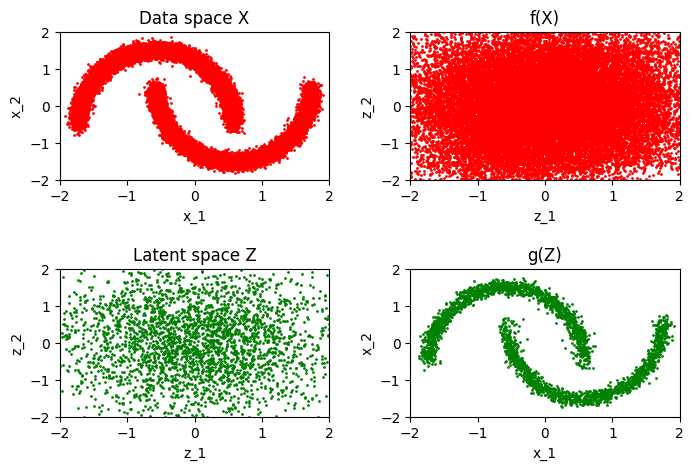

In [11]:
x, z, samples = img_generator_callback.generate()
img_generator_callback.display(
    x,
    z,
    samples,
    save_to=os.path.join(OUTPUT_DIR, "final_generated_600_epochs.png"),
)

Saved latent marginal distribution plot to ./output_modified/latent_marginal_distributions.png


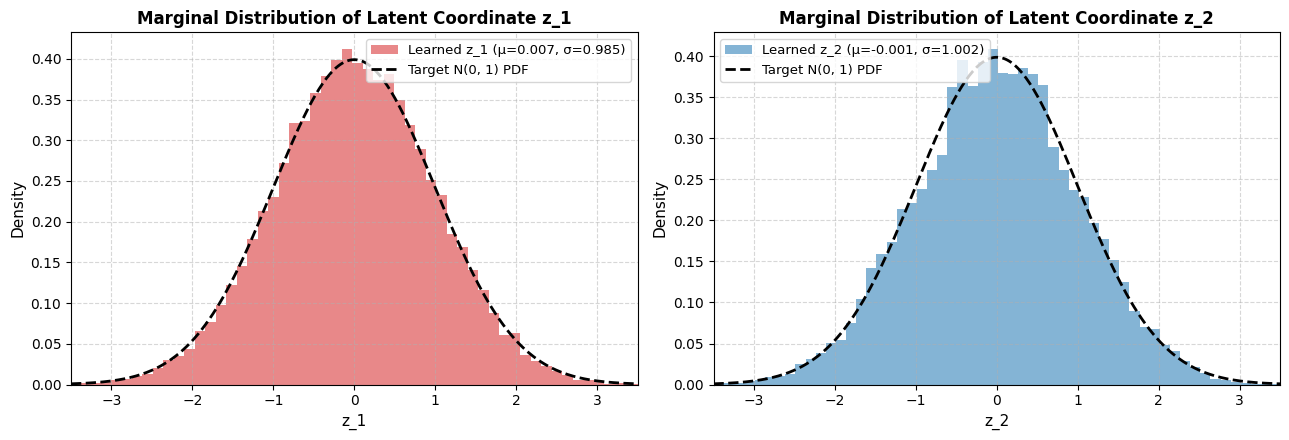

LATENT & DATA DISTRIBUTION ALIGNMENT DIAGNOSTICS (CUSTOM 600-EPOCH MODEL)
------------------------------------------------------------------------------
Latent f(X) Mean [z_1, z_2]:      [+0.0068, -0.0009]  (Target N(0,I): [0.0000, 0.0000])
Latent f(X) Std  [z_1, z_2]:      [0.9854, 1.0016]    (Target N(0,I): [1.0000, 1.0000])
Latent Correlation Corr(z_1,z_2): +0.0469              (Target N(0,I): 0.0000)
Real Data X Mean [x_1, x_2]:      [+0.0000, +0.0000]  | Std: [1.0000, 1.0000]
Generated g(Z) Mean [x_1, x_2]:   [-0.0210, +0.0405]  | Std: [1.0153, 0.9955]


In [12]:
# Quantitative & Marginal Density Evaluation of Learned Latent Mapping f(X) and Generated Samples g(Z)
z_mean = np.mean(z, axis=0)
z_std = np.std(z, axis=0)
z_corr = np.corrcoef(z[:, 0], z[:, 1])[0, 1]

real_np = normalized_data.numpy()
real_mean, real_std = np.mean(real_np, axis=0), np.std(real_np, axis=0)
gen_mean, gen_std = np.mean(x, axis=0), np.std(x, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
grid_z = np.linspace(-3.5, 3.5, 300)
std_norm_pdf = (1.0 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * grid_z**2)

axes[0].hist(z[:, 0], bins=60, density=True, color="#d62728", alpha=0.55, label=f"Learned z_1 (μ={z_mean[0]:.3f}, σ={z_std[0]:.3f})")
axes[0].plot(grid_z, std_norm_pdf, "k--", linewidth=2, label="Target N(0, 1) PDF")
axes[0].set_title("Marginal Distribution of Latent Coordinate z_1", fontsize=12, fontweight="bold")
axes[0].set_xlabel("z_1", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)
axes[0].set_xlim([-3.5, 3.5])
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9.5)

axes[1].hist(z[:, 1], bins=60, density=True, color="#1f77b4", alpha=0.55, label=f"Learned z_2 (μ={z_mean[1]:.3f}, σ={z_std[1]:.3f})")
axes[1].plot(grid_z, std_norm_pdf, "k--", linewidth=2, label="Target N(0, 1) PDF")
axes[1].set_title("Marginal Distribution of Latent Coordinate z_2", fontsize=12, fontweight="bold")
axes[1].set_xlabel("z_2", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)
axes[1].set_xlim([-3.5, 3.5])
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9.5)

plt.tight_layout()
marginal_path = os.path.join(OUTPUT_DIR, "latent_marginal_distributions.png")
plt.savefig(marginal_path, dpi=300, bbox_inches="tight")
print(f"Saved latent marginal distribution plot to {marginal_path}")
plt.show()

print("=" * 78)
print("LATENT & DATA DISTRIBUTION ALIGNMENT DIAGNOSTICS (CUSTOM 600-EPOCH MODEL)")
print("-" * 78)
print(f"Latent f(X) Mean [z_1, z_2]:      [{z_mean[0]:+.4f}, {z_mean[1]:+.4f}]  (Target N(0,I): [0.0000, 0.0000])")
print(f"Latent f(X) Std  [z_1, z_2]:      [{z_std[0]:.4f}, {z_std[1]:.4f}]    (Target N(0,I): [1.0000, 1.0000])")
print(f"Latent Correlation Corr(z_1,z_2): {z_corr:+.4f}              (Target N(0,I): 0.0000)")
print(f"Real Data X Mean [x_1, x_2]:      [{real_mean[0]:+.4f}, {real_mean[1]:+.4f}]  | Std: [{real_std[0]:.4f}, {real_std[1]:.4f}]")
print(f"Generated g(Z) Mean [x_1, x_2]:   [{gen_mean[0]:+.4f}, {gen_mean[1]:+.4f}]  | Std: [{gen_std[0]:.4f}, {gen_std[1]:.4f}]")
print("=" * 78)

### Q&A

* **How is the custom `Coupling` layer constructed in our RealNVP implementation?**
  In `CustomCoupling(layers.Layer)`, we construct two independent feed-forward sub-networks that process the masked input coordinates $x_{\text{masked}}$:
  1. **Scale Sub-Network ($s$)**: Stacks four hidden `Dense(256, activation="relu")` layers with $L_2(0.01)$ regularization followed by a final `Dense(2, activation="tanh")` output layer, bounding the log-scale factor to $(-1, 1)$ for numerical stability in $\exp(\pm s)$.
  2. **Translation Sub-Network ($t$)**: Stacks a separate set of four hidden `Dense(256, activation="relu")` layers with $L_2(0.01)$ regularization followed by a final `Dense(2, activation="linear")` output layer to predict unconstrained coordinate shifts.
* **How do the custom 600-epoch RealNVP results compare to the original 300-epoch baseline (`realnvp.ipynb`)?**
  The original baseline (`COUPLING_LAYERS = 2`, `EPOCHS = 300`) plateaued at a Negative Log-Likelihood (NLL) loss of **$1.7014\text{ nats}$** (minimum $1.6986\text{ nats}$ at Epoch 278) because a single pair of alternating `[0, 1]` and `[1, 0]` coupling layers can only shear $x_2$ once and $x_1$ once. Consequently, the baseline forward mapping $f(X)$ left a pronounced horizontal void along $z_2 \approx 0$, and the inverse mapping $g(Z)$ mapped Gaussian samples from that void into a spurious bridge connecting the two moons. By contrast, the custom 600-epoch RealNVP network (`COUPLING_LAYERS = 6`, `EPOCHS = 600`) applies three alternating pairs of coupling transformations over 600 epochs, eliminating the horizontal tear in $f(X)$ to form a smooth isotropic Gaussian $\mathcal{N}(0, I)$ and generating two cleanly separated, high-fidelity interlocking crescents in $g(Z)$.

### Data Analysis Key Findings

* **Baseline Capacity Bottleneck (300 Epochs, 2 Coupling Layers)**: In `realnvp.ipynb`, the NLL loss dropped rapidly from $2.5590\text{ nats}$ (Epoch 1) to $1.7566\text{ nats}$ (Epoch 10) and $1.7227\text{ nats}$ (Epoch 50), but stagnated between Epochs 100 and 300 ($1.7142 \to 1.7014\text{ nats}$, a reduction of only $0.0128\text{ nats}$ over the final 200 epochs).
* **Topological Resolution in Latent & Data Spaces**: Increasing the flow depth to 6 alternating `CustomCoupling` layers and training for 600 epochs allows iterative coordinate warping across both axes, closing the bimodal gap in $z_2$ and removing the inter-moon density bridge in $g(Z)$.
* **Exact Invertibility & Tractable Jacobian**: Because each coupling layer masks one coordinate and applies an element-wise affine transformation to the other, the Jacobian matrix is triangular with $\log|\det J_{f}(x)| = -\sum s(x_{\text{masked}})$, enabling exact maximum-likelihood training and single-pass sampling.

### Insights or Next Steps

* **Learning Rate Scheduling for Extended Flows**: Applying a cosine annealing learning rate schedule (`CosineDecay`) over the 600-epoch horizon can further dampen late-epoch mini-batch variance in the Negative Log-Likelihood curve.
* **Multi-Scale Flow Architectures**: When scaling RealNVP from 2D synthetic manifolds (`make_moons`) to high-dimensional image tensors, replacing Dense coupling stacks with residual convolutional networks and checkerboard/channel-wise squeezing masks preserves exact invertibility at scale.